In [1]:
!git clone -b megha-work https://github.com/meghagangal362015/cmpe257-early-reading-prediction.git

%cd cmpe257-early-reading-prediction

Cloning into 'cmpe257-early-reading-prediction'...
remote: Enumerating objects: 83, done.
remote: Counting objects: 100% (83/83), done.
remote: Compressing objects: 100% (66/66), done.
remote: Total 83 (delta 25), reused 58 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (83/83), 1010.68 KiB | 10.53 MiB/s, done.
Resolving deltas: 100% (25/25), done.
/content/cmpe257-early-reading-prediction


In [2]:
import pandas as pd

rf_results = pd.read_csv(
    "results/random_forest_cv_fold_results.csv"
)

xgb_results = pd.read_csv(
    "results/xgboost_cv_fold_results.csv"
)

print("Random Forest results:")
display(rf_results)

print("XGBoost results:")
display(xgb_results)

Random Forest results:


,Target,Fold,Accuracy,PR-AUC
0,Word Identification,1,0.654930,0.689135
1,Word Identification,2,0.591549,0.626034
2,Word Identification,3,0.735714,0.850991
3,Word Identification,4,0.585714,0.626571
4,Word Identification,5,0.619718,0.667110
5,Word Attack,1,0.549296,0.614459
6,Word Attack,2,0.626761,0.705542
7,Word Attack,3,0.621429,0.745323
8,Word Attack,4,0.507143,0.521790
9,Word Attack,5,0.626761,0.755710


XGBoost results:


,Target,Fold,Accuracy,PR-AUC
0,Word Identification,1,0.605634,0.707398
1,Word Identification,2,0.605634,0.653924
2,Word Identification,3,0.685714,0.846340
3,Word Identification,4,0.600000,0.572065
4,Word Identification,5,0.591549,0.637859
5,Word Attack,1,0.521127,0.607409
6,Word Attack,2,0.669014,0.704177
7,Word Attack,3,0.600000,0.801418
8,Word Attack,4,0.585714,0.544714
9,Word Attack,5,0.697183,0.735387


In [3]:
# Add model names

rf_results["Model"] = "Random Forest"
xgb_results["Model"] = "XGBoost"

# Combine fold-level results
all_results = pd.concat(
    [rf_results, xgb_results],
    ignore_index=True
)

# Calculate mean and standard deviation
comparison = (
    all_results
    .groupby(["Target", "Model"])[["Accuracy", "PR-AUC"]]
    .agg(["mean", "std"])
    .round(4)
)

display(comparison)

Accuracy          PR-AUC        
                                      mean     std    mean     std
Target              Model                                         
Word Attack         Random Forest   0.5863  0.0551  0.6686  0.0992
                    XGBoost         0.6146  0.0699  0.6786  0.1024
Word Identification Random Forest   0.6375  0.0614  0.6920  0.0929
                    XGBoost         0.6177  0.0385  0.6835  0.1030

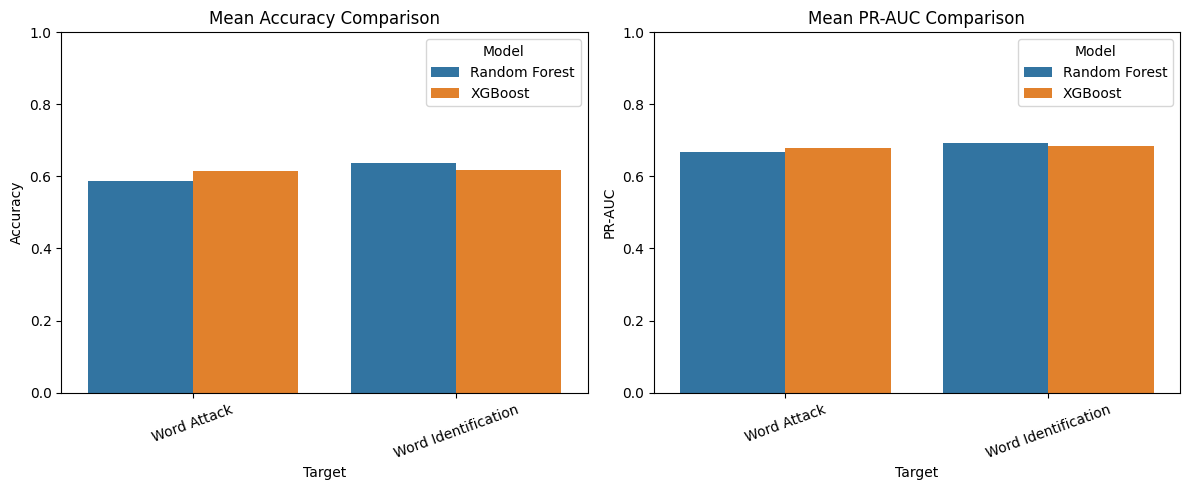

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = (
    all_results
    .groupby(["Target", "Model"])[["Accuracy", "PR-AUC"]]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=plot_data,
    x="Target",
    y="Accuracy",
    hue="Model",
    ax=axes[0]
)

axes[0].set_title("Mean Accuracy Comparison")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=plot_data,
    x="Target",
    y="PR-AUC",
    hue="Model",
    ax=axes[1]
)

axes[1].set_title("Mean PR-AUC Comparison")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [5]:
import os

os.makedirs("results", exist_ok=True)

comparison.to_csv(
    "results/random_forest_vs_xgboost_comparison.csv"
)

plot_data.to_csv(
    "results/random_forest_vs_xgboost_mean_results.csv",
    index=False
)

print("Comparison results saved.")

Comparison results saved.
